In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import zipfile
from pathlib import Path

# ZIP file location in Google Drive
zip_path = Path("/content/drive/MyDrive/Brain Tumor MRI Dataset/mri.zip")

# Extract dataset to Colab's temporary storage
extract_path = Path("/content/brain_tumor_mri")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: /content/brain_tumor_mri


In [4]:
DATA_DIR = Path("/content/brain_tumor_mri")

TRAIN_DIR = DATA_DIR / "Training"
TEST_DIR = DATA_DIR / "Testing"

print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Training directory exists: True
Testing directory exists: True


In [5]:
# File handling and data processing
import os
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

# Image visualization
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Deep learning — PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Reproducibility
import random

In [6]:
from pathlib import Path

DATA_DIR = Path("/content/brain_tumor_mri")
TRAIN_DIR = DATA_DIR / "Training"
TEST_DIR = DATA_DIR / "Testing"

for split_dir in [TRAIN_DIR, TEST_DIR]:
    print(f"\n{split_dir.name}")

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            images = [
                f for f in class_dir.iterdir()
                if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
            ]
            print(f"{class_dir.name}: {len(images)} images")


Training
glioma: 1400 images
meningioma: 1400 images
notumor: 1400 images
pituitary: 1400 images

Testing
glioma: 400 images
meningioma: 400 images
notumor: 400 images
pituitary: 400 images


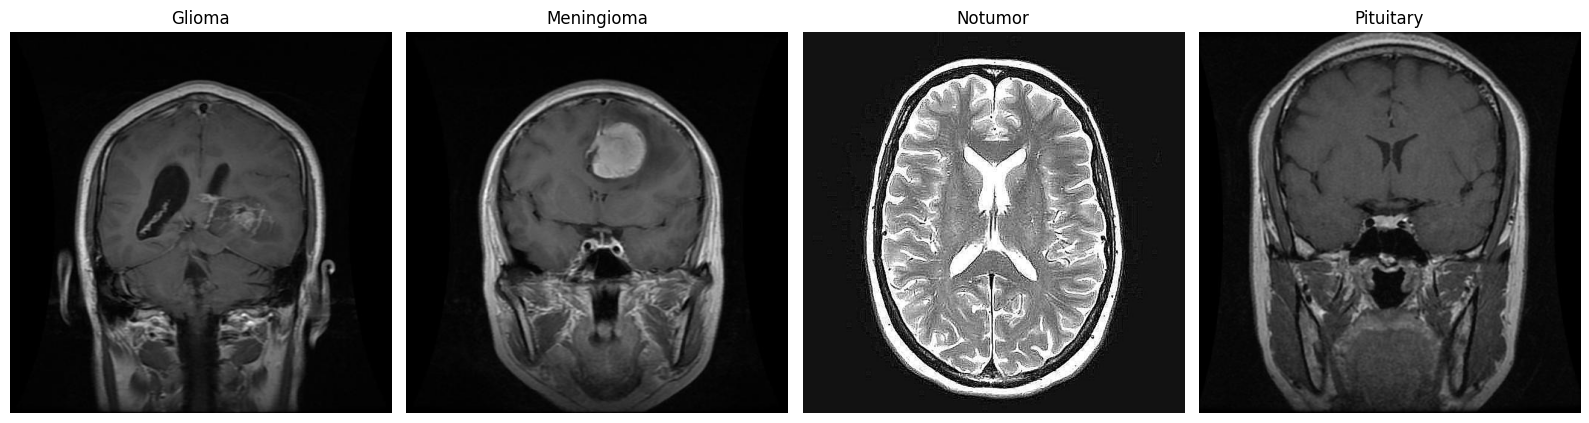

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = ["glioma", "meningioma", "notumor", "pituitary"]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, class_name in zip(axes, classes):
    class_path = TRAIN_DIR / class_name
    image_files = list(class_path.glob("*"))

    image_path = random.choice(image_files)
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from collections import Counter
from PIL import Image

image_sizes = Counter()
image_formats = Counter()

for class_name in classes:
    image_files = list((TRAIN_DIR / class_name).glob("*"))

    for image_path in image_files:
        try:
            with Image.open(image_path) as img:
                image_sizes[img.size] += 1
                image_formats[img.format] += 1
        except Exception:
            continue

print("Image formats:")
print(image_formats.most_common())

print("\nMost common image dimensions (width, height):")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

print(f"\nUnique image dimensions: {len(image_sizes)}")

Image formats:
[('JPEG', 5596), ('PNG', 4)]

Most common image dimensions (width, height):
(512, 512): 4012 images
(225, 225): 253 images
(630, 630): 69 images
(201, 251): 40 images
(236, 236): 39 images
(442, 442): 38 images
(150, 198): 33 images
(228, 221): 32 images
(232, 217): 32 images
(428, 417): 31 images

Unique image dimensions: 381


In [9]:
from PIL import Image

corrupted_images = []

for class_name in classes:
    for image_path in (TRAIN_DIR / class_name).iterdir():
        if image_path.is_file():
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupted_images.append(str(image_path))

print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print(*corrupted_images[:10], sep="\n")
else:
    print("All training images are readable.")

Corrupted images: 0
All training images are readable.


In [10]:
for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Testing", TEST_DIR)
]:
    print(f"\n{split_name} distribution:")

    for class_name in classes:
        class_dir = split_dir / class_name

        count = sum(
            1 for f in class_dir.iterdir()
            if f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )

        print(f"{class_name}: {count}")


Training distribution:
glioma: 1400
meningioma: 1400
notumor: 1400
pituitary: 1400

Testing distribution:
glioma: 400
meningioma: 400
notumor: 400
pituitary: 400


In [11]:
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA available:", torch.cuda.is_available())
else:
    print("GPU not available. Enable it in Runtime → Change runtime type → T4 GPU.")

GPU: Tesla T4
CUDA available: True


In [12]:
from torchvision import transforms

IMG_SIZE = 224

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [13]:
from torchvision import datasets
from torch.utils.data import random_split
import torch

# Load the original training dataset
full_train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transforms
)

# Reproducible, stratified split: 80% train, 20% validation
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

indices = list(range(len(full_train_dataset)))
labels = full_train_dataset.targets

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_dataset = Subset(full_train_dataset, train_indices)

# Validation must use test transforms, not random training augmentation
full_val_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=test_transforms
)
val_dataset = Subset(full_val_dataset, val_indices)

# Keep the official test set separate
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transforms
)

print("Classes:", full_train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training images: 4480
Validation images: 1120
Testing images: 1600


In [14]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 140
Validation batches: 35
Testing batches: 50


In [15]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Class names:", full_train_dataset.classes)
print("Labels in batch:", labels[:10].tolist())
print("Image data type:", images.dtype)


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Labels in batch: [3, 3, 0, 0, 2, 3, 2, 0, 1, 1]
Image data type: torch.float32


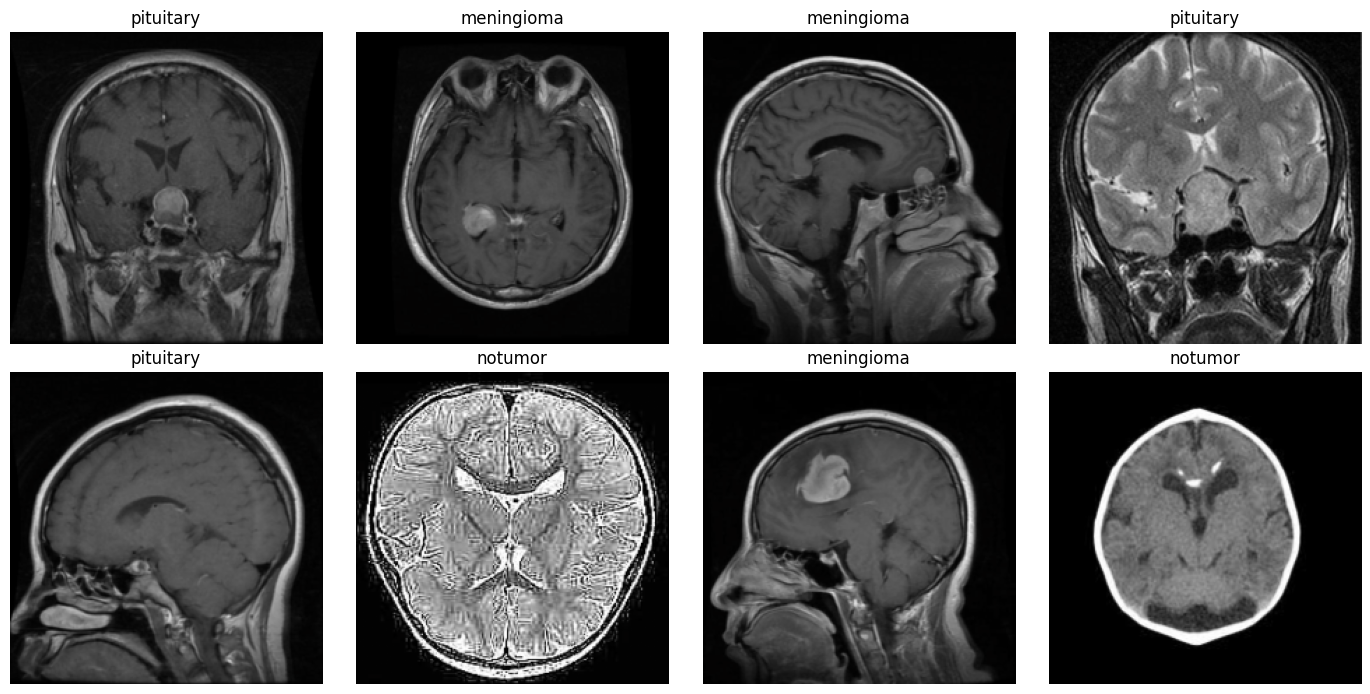

In [16]:
import matplotlib.pyplot as plt
import torchvision

# Get one batch from the training loader
images, labels = next(iter(train_loader))

# Display the first 8 images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    # Reverse ImageNet normalization for visualization
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = images[i] * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()

    class_name = full_train_dataset.classes[labels[i].item()]

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


ResNet-50 is a 50-layer deep learning architecture that uses residual connections to learn complex image features. RadImageNet provides pretrained weights learned from radiological images, which may help the model recognize medical image patterns. We chose this combination for our four-class brain MRI classification task—glioma, meningioma, pituitary tumor, and no tumor—because transfer learning can reduce training time and improve learning efficiency compared with training from scratch. Its effectiveness will be evaluated on the held-out test dataset.

In [18]:
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 4

model = models.resnet50(weights=None)

# Replace the final classification layer
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, NUM_CLASSES)

print(model.fc)

Linear(in_features=2048, out_features=4, bias=True)


In [19]:
!wget -O ResNet50_RadImageNet.pt \
"https://huggingface.co/Lab-Rasool/RadImageNet/resolve/main/ResNet50.pt"

--2026-11-01 18:31:07--  https://huggingface.co/Lab-Rasool/RadImageNet/resolve/main/ResNet50.pt
Resolving huggingface.co (huggingface.co)... 99.86.101.36, 99.86.101.39, 99.86.101.56, ...
Connecting to huggingface.co (huggingface.co)|99.86.101.36|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/686ac07019fc81228e32bbfa/442a77ca0f91d3578b7551201a063d060dbd7ac2e0b9f7330fe12de10ff0e743?xip=64EWTY1Bzes&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27ResNet50.pt%3B+filename%3D%22ResNet50.pt%22%3B&user_id=public&X-Xet-Cas-Uid=public&Expires=1793561467&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjg2YWMwNzAxOWZjODEyMjhlMzJiYmZhLzQ0MmE3N2NhMGY5MWQzNTc4Yjc1NTEyMDFhMDYzZDA2MGRiZDdhYzJlMGI5ZjczMzBmZTEyZGUxMGZmMGU3NDNcXD94aXA9NjRFV1RZMUJ6ZXMmcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvbj0qJnVzZXJfaWQ9cHVibGljJlgtWGV0LUNhcy1VaWQ9cHVibGljIiwiQ29uZGl0aW9uIjp7IkRhdGVMZXNzVGhhbiI

In [20]:
import torch
from pathlib import Path

checkpoint_path = Path("/content/ResNet50_RadImageNet.pt")

if not checkpoint_path.exists():
    print("Checkpoint file not found. Check whether the download succeeded.")
else:
    print(f"Checkpoint size: {checkpoint_path.stat().st_size / (1024**2):.2f} MB")

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys())[:20])

        if all(torch.is_tensor(v) for v in checkpoint.values()):
            print("This appears to be a direct state dictionary.")
        else:
            for key, value in checkpoint.items():
                if isinstance(value, dict):
                    print(f"{key}: nested dictionary with {len(value)} entries")

Checkpoint size: 89.98 MB
Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['backbone.0.weight', 'backbone.1.weight', 'backbone.1.bias', 'backbone.1.running_mean', 'backbone.1.running_var', 'backbone.1.num_batches_tracked', 'backbone.4.0.conv1.weight', 'backbone.4.0.bn1.weight', 'backbone.4.0.bn1.bias', 'backbone.4.0.bn1.running_mean', 'backbone.4.0.bn1.running_var', 'backbone.4.0.bn1.num_batches_tracked', 'backbone.4.0.conv2.weight', 'backbone.4.0.bn2.weight', 'backbone.4.0.bn2.bias', 'backbone.4.0.bn2.running_mean', 'backbone.4.0.bn2.running_var', 'backbone.4.0.bn2.num_batches_tracked', 'backbone.4.0.conv3.weight', 'backbone.4.0.bn3.weight']
This appears to be a direct state dictionary.


In [21]:
# Inspect checkpoint architecture and key shapes
print("Total checkpoint parameters:", len(checkpoint))

for key in list(checkpoint.keys())[:10]:
    print(key, checkpoint[key].shape)

print("\nOur model's first layer:")
print("conv1.weight:", model.conv1.weight.shape)

print("\nCheckpoint's first layer:")
print("backbone.0.weight:", checkpoint["backbone.0.weight"].shape)

Total checkpoint parameters: 318
backbone.0.weight torch.Size([64, 3, 7, 7])
backbone.1.weight torch.Size([64])
backbone.1.bias torch.Size([64])
backbone.1.running_mean torch.Size([64])
backbone.1.running_var torch.Size([64])
backbone.1.num_batches_tracked torch.Size([])
backbone.4.0.conv1.weight torch.Size([64, 64, 1, 1])
backbone.4.0.bn1.weight torch.Size([64])
backbone.4.0.bn1.bias torch.Size([64])
backbone.4.0.bn1.running_mean torch.Size([64])

Our model's first layer:
conv1.weight: torch.Size([64, 3, 7, 7])

Checkpoint's first layer:
backbone.0.weight: torch.Size([64, 3, 7, 7])


In [22]:
model_keys = set(model.state_dict().keys())
checkpoint_keys = set(checkpoint.keys())

print("Model parameters:", len(model_keys))
print("Checkpoint parameters:", len(checkpoint_keys))

# Check the backbone key mapping
mapped_keys = {
    key.replace("backbone.", "", 1)
    for key in checkpoint_keys
    if key.startswith("backbone.")
}

matching_keys = model_keys.intersection(mapped_keys)

print("Matching keys after removing 'backbone.':", len(matching_keys))
print("Example mapped keys:", list(sorted(matching_keys))[:10])

Model parameters: 320
Checkpoint parameters: 318
Matching keys after removing 'backbone.': 0
Example mapped keys: []


In [23]:
print("First 20 checkpoint keys:")
for key in list(checkpoint.keys())[:20]:
    print(key)

print("\nLast 20 checkpoint keys:")
for key in list(checkpoint.keys())[-20:]:
    print(key)

First 20 checkpoint keys:
backbone.0.weight
backbone.1.weight
backbone.1.bias
backbone.1.running_mean
backbone.1.running_var
backbone.1.num_batches_tracked
backbone.4.0.conv1.weight
backbone.4.0.bn1.weight
backbone.4.0.bn1.bias
backbone.4.0.bn1.running_mean
backbone.4.0.bn1.running_var
backbone.4.0.bn1.num_batches_tracked
backbone.4.0.conv2.weight
backbone.4.0.bn2.weight
backbone.4.0.bn2.bias
backbone.4.0.bn2.running_mean
backbone.4.0.bn2.running_var
backbone.4.0.bn2.num_batches_tracked
backbone.4.0.conv3.weight
backbone.4.0.bn3.weight

Last 20 checkpoint keys:
backbone.7.1.bn3.running_var
backbone.7.1.bn3.num_batches_tracked
backbone.7.2.conv1.weight
backbone.7.2.bn1.weight
backbone.7.2.bn1.bias
backbone.7.2.bn1.running_mean
backbone.7.2.bn1.running_var
backbone.7.2.bn1.num_batches_tracked
backbone.7.2.conv2.weight
backbone.7.2.bn2.weight
backbone.7.2.bn2.bias
backbone.7.2.bn2.running_mean
backbone.7.2.bn2.running_var
backbone.7.2.bn2.num_batches_tracked
backbone.7.2.conv3.weight
back

In [24]:
# Map RadImageNet checkpoint keys to torchvision ResNet-50 keys
mapped_checkpoint = {}

for key, value in checkpoint.items():
    if key.startswith("backbone.0."):
        new_key = key.replace("backbone.0.", "conv1.", 1)

    elif key.startswith("backbone.1."):
        new_key = key.replace("backbone.1.", "bn1.", 1)

    elif key.startswith("backbone."):
        parts = key.split(".", 2)
        layer_map = {
            "4": "layer1",
            "5": "layer2",
            "6": "layer3",
            "7": "layer4",
        }

        if len(parts) < 3 or parts[1] not in layer_map:
            continue

        new_key = f"{layer_map[parts[1]]}.{parts[2]}"

    else:
        continue

    mapped_checkpoint[new_key] = value

# Verify and load the weights
result = model.load_state_dict(mapped_checkpoint, strict=False)

print("Mapped checkpoint tensors:", len(mapped_checkpoint))
print("Missing model keys:", result.missing_keys)
print("Unexpected checkpoint keys:", result.unexpected_keys)

Mapped checkpoint tensors: 318
Missing model keys: ['fc.weight', 'fc.bias']
Unexpected checkpoint keys: []


In [26]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Device:", device)
print("Model device:", next(model.parameters()).device)
print("Output classes:", model.fc.out_features)

Device: cuda
Model device: cuda:0
Output classes: 4


In [27]:
# Freeze all pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the new 4-class classification head
for param in model.fc.parameters():
    param.requires_grad = True

# Verify
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print(f"Trainable percentage: {100 * trainable / total:.2f}%")

Trainable parameters: 8,196
Total parameters: 23,516,228
Trainable percentage: 0.03%


In [28]:
import torch.nn as nn
import torch.optim as optim

# Multi-class classification loss
criterion = nn.CrossEntropyLoss()

# Optimize only the trainable classification head
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [29]:
from tqdm.auto import tqdm
import torch

EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Training Accuracy: {epoch_accuracy:.4f}"
    )

Epoch 1/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [1/5] Loss: 0.9114 | Training Accuracy: 0.6658


Epoch 2/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [2/5] Loss: 0.5999 | Training Accuracy: 0.8002


Epoch 3/5:   0%|          | 0/140 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79ed7e54c0e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79ed7e54c0e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [3/5] Loss: 0.5343 | Training Accuracy: 0.8125


Epoch 4/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [4/5] Loss: 0.4617 | Training Accuracy: 0.8464


Epoch 5/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [5/5] Loss: 0.4459 | Training Accuracy: 0.8489


In [30]:
model.eval()

correct = 0
total = 0
val_loss = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        val_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Validation Loss: {val_loss / total:.4f}")
print(f"Validation Accuracy: {100 * correct / total:.2f}%")

Validation Loss: 0.4283
Validation Accuracy: 83.93%


In [31]:
# Freeze the entire model first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the last ResNet-50 block
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep the 4-class classification head trainable
for param in model.fc.parameters():
    param.requires_grad = True

# Use a smaller learning rate for pretrained features
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Trainable parameters: 14972932


In [32]:
from tqdm.auto import tqdm

EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Fine-tuning Epoch {epoch + 1}/{EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Loss: {running_loss / total:.4f} | "
        f"Training Accuracy: {100 * correct / total:.2f}%"
    )

Fine-tuning Epoch 1/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [1/5] Loss: 0.4106 | Training Accuracy: 86.52%


Fine-tuning Epoch 2/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [2/5] Loss: 0.3936 | Training Accuracy: 86.65%


Fine-tuning Epoch 3/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [3/5] Loss: 0.3718 | Training Accuracy: 87.63%


Fine-tuning Epoch 4/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [4/5] Loss: 0.3661 | Training Accuracy: 87.90%


Fine-tuning Epoch 5/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [5/5] Loss: 0.3541 | Training Accuracy: 87.77%


In [33]:
model.eval()

correct = 0
total = 0
val_loss = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        val_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Validation Loss: {val_loss / total:.4f}")
print(f"Validation Accuracy: {100 * correct / total:.2f}%")

Validation Loss: 0.3014
Validation Accuracy: 89.38%


Test Accuracy: 0.8213

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8967    0.6725    0.7686       400
  meningioma     0.7593    0.6625    0.7076       400
     notumor     0.7837    0.9875    0.8739       400
   pituitary     0.8613    0.9625    0.9091       400

    accuracy                         0.8213      1600
   macro avg     0.8253    0.8212    0.8148      1600
weighted avg     0.8253    0.8213    0.8148      1600



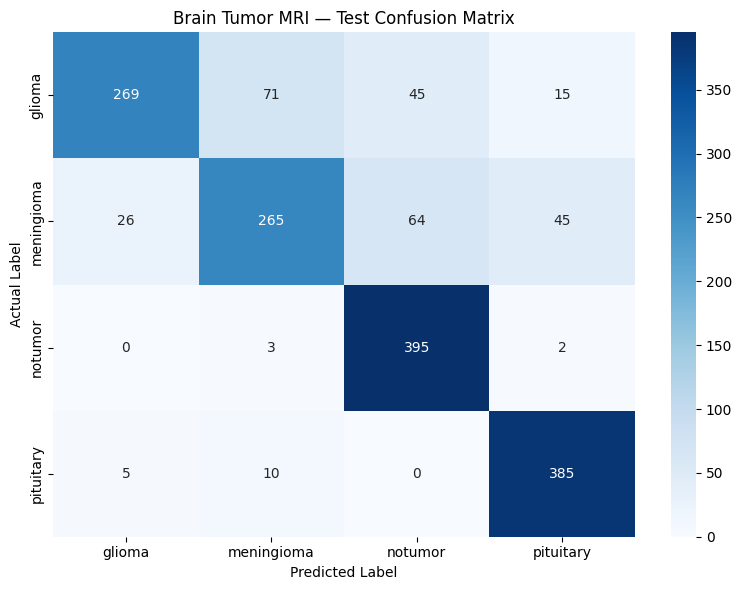

In [35]:
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = test_loader.dataset.classes

print(f"Test Accuracy: {accuracy_score(all_labels, all_preds):.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Brain Tumor MRI — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [36]:
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": test_loader.dataset.classes,
    "img_size": IMG_SIZE,
    "architecture": "resnet50_radimagenet"
}, "/content/brain_tumor_resnet50_radimagenet.pth")

print("Model saved successfully.")

Model saved successfully.


In [37]:
from google.colab import files

files.download("/content/brain_tumor_resnet50_radimagenet.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

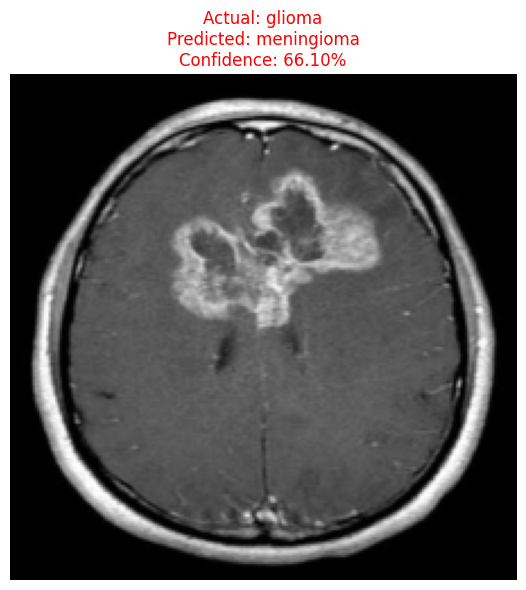

In [62]:
import matplotlib.pyplot as plt
import torch

model.eval()

# Get one image from the test dataset
image, true_label = test_dataset[0]

# Predict
with torch.no_grad():
    logits = model(image.unsqueeze(0).to(device))
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_idx = probabilities.argmax().item()
class_names = test_dataset.classes
confidence = probabilities[predicted_idx].item()

# Reverse ImageNet normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = (image.cpu() * std + mean).clamp(0, 1)

# Display image and prediction
plt.figure(figsize=(6, 6))
plt.imshow(display_image.permute(1, 2, 0).numpy())

correct = predicted_idx == true_label

plt.title(
    f"Actual: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_idx]}\n"
    f"Confidence: {confidence:.2%}",
    color="green" if correct else "red"
)

plt.axis("off")
plt.tight_layout()
plt.show()

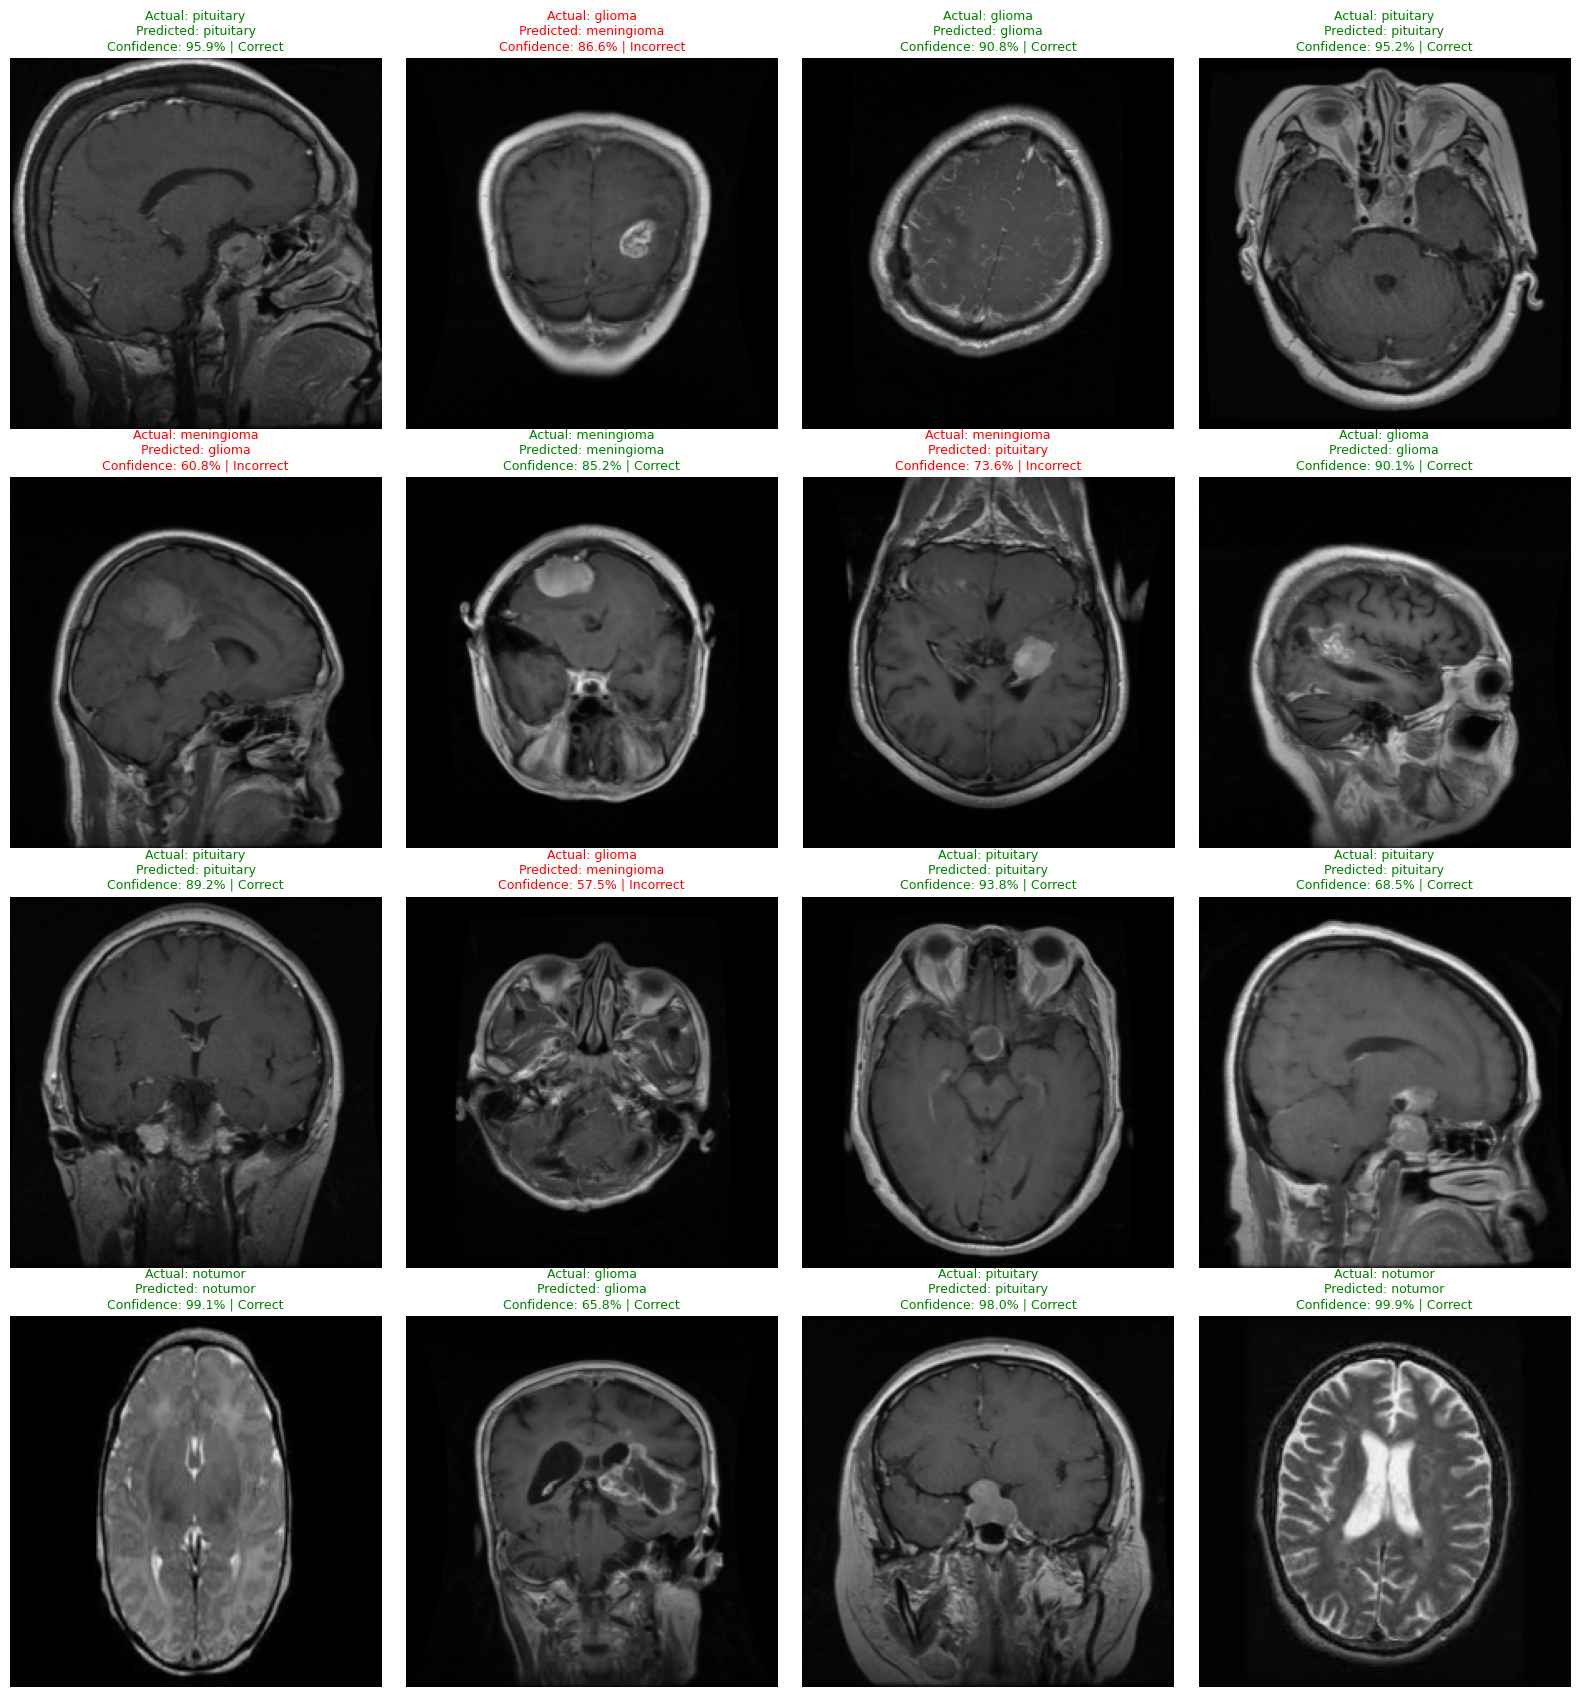

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
import random
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import models
from google.colab import files

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load fine-tuned RadImageNet ResNet-50
checkpoint = torch.load(
    "/content/brain_tumor_resnet50_radimagenet.pth",
    map_location=device,
    weights_only=True
)

class_names = checkpoint["class_names"]

model_resnet = models.resnet50(weights=None)
model_resnet.fc = nn.Linear(
    model_resnet.fc.in_features,
    len(class_names)
)

model_resnet.load_state_dict(checkpoint["model_state_dict"])
model_resnet = model_resnet.to(device)
model_resnet.eval()

# Select 16 random test images
test_dataset = test_loader.dataset

random.seed(42)
indices = random.sample(range(len(test_dataset)), 16)

# Create 4 × 4 grid
fig, axes = plt.subplots(4, 4, figsize=(16, 17))

# ImageNet normalization values
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for ax, idx in zip(axes.flat, indices):
    image_tensor, actual_label = test_dataset[idx]

    # Predict
    with torch.no_grad():
        outputs = model_resnet(
            image_tensor.unsqueeze(0).to(device)
        )

        probabilities = torch.softmax(outputs, dim=1)[0]
        predicted_label = probabilities.argmax().item()
        confidence = probabilities[predicted_label].item() * 100

    # Reverse normalization for correct image display
    display_image = (
        image_tensor.cpu() * std + mean
    ).clamp(0, 1)

    ax.imshow(display_image.permute(1, 2, 0).numpy())
    ax.axis("off")

    # Correct / incorrect status
    correct = predicted_label == actual_label
    status = "Correct" if correct else "Incorrect"

    ax.set_title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1f}% | {status}",
        color="green" if correct else "red",
        fontsize=9
    )

plt.tight_layout()

# Save high-resolution PNG
output_path = (
    "/content/resnet50-radimagenet-prediction-examples.png"
)

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# Download PNG
files.download(output_path)

In [43]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ImageNet-pretrained MobileNetV3-Large
model_mobilenet = models.mobilenet_v3_large(
    weights=models.MobileNet_V3_Large_Weights.DEFAULT
)

# Replace the final classification layer
in_features = model_mobilenet.classifier[3].in_features
model_mobilenet.classifier[3] = nn.Linear(in_features, 4)

model_mobilenet = model_mobilenet.to(device)

print("Device:", device)
print("Classification head:", model_mobilenet.classifier[3])
print("Output classes:", model_mobilenet.classifier[3].out_features)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 115MB/s]


Device: cuda
Classification head: Linear(in_features=1280, out_features=4, bias=True)
Output classes: 4


In [44]:
# Freeze all MobileNet parameters
for param in model_mobilenet.parameters():
    param.requires_grad = False

# Unfreeze the final classification layer
for param in model_mobilenet.classifier[3].parameters():
    param.requires_grad = True

# Loss and optimizer
criterion_mobilenet = nn.CrossEntropyLoss()

optimizer_mobilenet = torch.optim.Adam(
    model_mobilenet.classifier[3].parameters(),
    lr=0.001
)

trainable = sum(
    p.numel() for p in model_mobilenet.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {trainable:,}")

Trainable parameters: 5,124


In [45]:
from tqdm.auto import tqdm

EPOCHS = 5

for epoch in range(EPOCHS):
    model_mobilenet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        train_loader, desc=f"MobileNet Epoch {epoch + 1}/{EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer_mobilenet.zero_grad()

        outputs = model_mobilenet(images)
        loss = criterion_mobilenet(outputs, labels)

        loss.backward()
        optimizer_mobilenet.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Loss: {running_loss / total:.4f} | "
        f"Training Accuracy: {100 * correct / total:.2f}%"
    )

MobileNet Epoch 1/5:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch [1/5] Loss: 0.6471 | Training Accuracy: 80.07%


MobileNet Epoch 2/5:   0%|          | 0/140 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79ed7e54c0e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Epoch [2/5] Loss: 0.3932 | Training Accuracy: 87.66%


MobileNet Epoch 3/5:   0%|          | 0/140 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch [4/5] Loss: 0.3048 | Training Accuracy: 90.13%


MobileNet Epoch 5/5:   0%|          | 0/140 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79ed7e54c0e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79ed7e54c0e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [5/5] Loss: 0.2831 | Training Accuracy: 90.38%


In [46]:
model_mobilenet.eval()

correct = 0
total = 0
val_loss = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        loss = criterion_mobilenet(outputs, labels)

        val_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Validation Loss: {val_loss / total:.4f}")
print(f"Validation Accuracy: {100 * correct / total:.2f}%")

Validation Loss: 0.2794
Validation Accuracy: 90.27%


MobileNetV3-Large Test Accuracy: 0.8381

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9730    0.6300    0.7648       400
  meningioma     0.7133    0.7900    0.7497       400
     notumor     0.8115    0.9900    0.8919       400
   pituitary     0.9195    0.9425    0.9309       400

    accuracy                         0.8381      1600
   macro avg     0.8543    0.8381    0.8343      1600
weighted avg     0.8543    0.8381    0.8343      1600



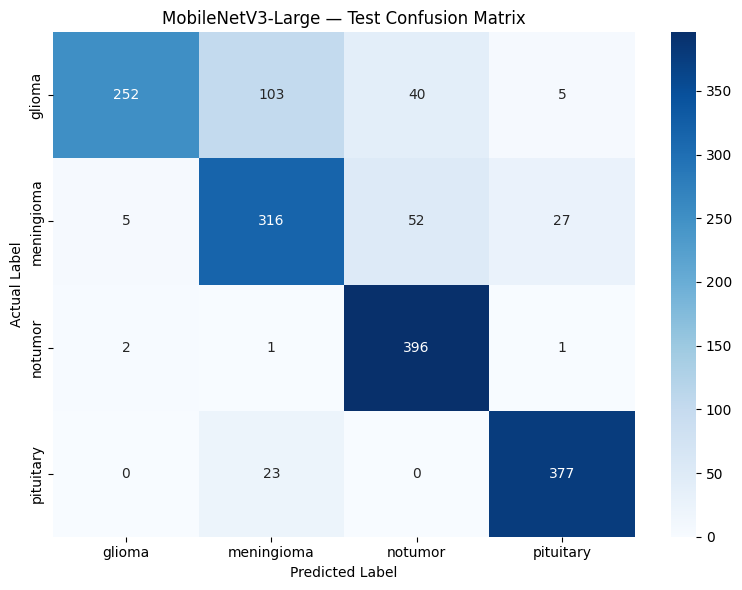

In [47]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_mobilenet.eval()

all_preds_mobilenet = []
all_labels_mobilenet = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_mobilenet(images)
        predictions = outputs.argmax(dim=1)

        all_preds_mobilenet.extend(predictions.cpu().numpy())
        all_labels_mobilenet.extend(labels.numpy())

class_names = test_loader.dataset.classes

print(
    f"MobileNetV3-Large Test Accuracy: "
    f"{accuracy_score(all_labels_mobilenet, all_preds_mobilenet):.4f}"
)

print("\nClassification Report:")
print(classification_report(
    all_labels_mobilenet,
    all_preds_mobilenet,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(
    all_labels_mobilenet,
    all_preds_mobilenet,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV3-Large — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [48]:
# Unfreeze the final feature block
for param in model_mobilenet.features[-1].parameters():
    param.requires_grad = True

# Keep the classifier trainable
for param in model_mobilenet.classifier.parameters():
    param.requires_grad = True

# Separate learning rates for pretrained features and classifier
optimizer_mobilenet = torch.optim.Adam([
    {
        "params": model_mobilenet.features[-1].parameters(),
        "lr": 1e-5
    },
    {
        "params": model_mobilenet.classifier.parameters(),
        "lr": 1e-4
    }
])

print("Final feature block and classifier are trainable.")

Final feature block and classifier are trainable.


In [49]:
EPOCHS_FINE = 5

for epoch in range(EPOCHS_FINE):
    model_mobilenet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_mobilenet.zero_grad()

        outputs = model_mobilenet(images)
        loss = criterion_mobilenet(outputs, labels)

        loss.backward()
        optimizer_mobilenet.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{EPOCHS_FINE}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}%"
    )

Epoch [1/5] Train Loss: 0.2703 | Train Accuracy: 90.58%
Epoch [2/5] Train Loss: 0.2404 | Train Accuracy: 91.25%
Epoch [3/5] Train Loss: 0.2230 | Train Accuracy: 91.90%
Epoch [4/5] Train Loss: 0.2058 | Train Accuracy: 92.63%
Epoch [5/5] Train Loss: 0.1951 | Train Accuracy: 93.35%


In [50]:
model_mobilenet.eval()

val_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        loss = criterion_mobilenet(outputs, labels)

        val_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Validation Loss: {val_loss / total:.4f}")
print(f"Validation Accuracy: {100 * correct / total:.2f}%")

Validation Loss: 0.1967
Validation Accuracy: 93.21%


Fine-tuned MobileNetV3-Large Test Accuracy: 0.8844
Test Accuracy: 88.44%

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9666    0.7225    0.8269       400
  meningioma     0.8182    0.8325    0.8253       400
     notumor     0.8780    0.9900    0.9307       400
   pituitary     0.8962    0.9925    0.9419       400

    accuracy                         0.8844      1600
   macro avg     0.8897    0.8844    0.8812      1600
weighted avg     0.8897    0.8844    0.8812      1600



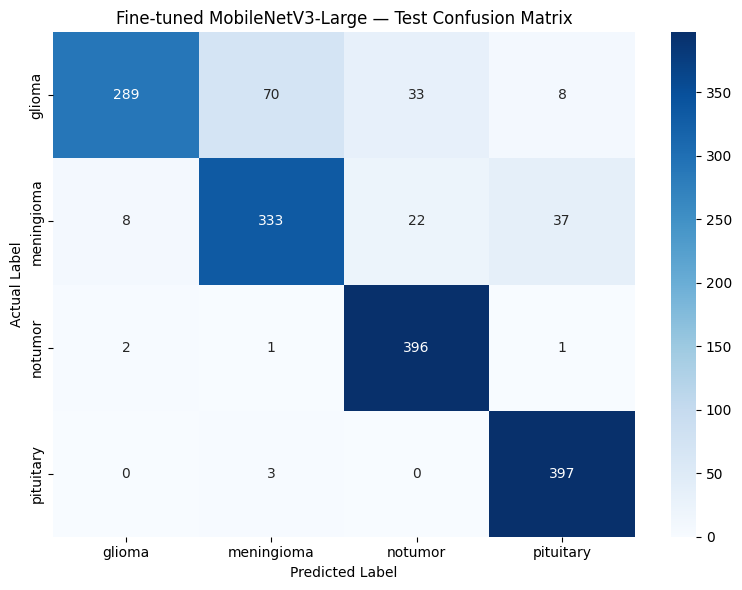

In [51]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_mobilenet.eval()

all_preds_mobilenet = []
all_labels_mobilenet = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_mobilenet(images)
        predictions = outputs.argmax(dim=1)

        all_preds_mobilenet.extend(predictions.cpu().numpy())
        all_labels_mobilenet.extend(labels.numpy())

class_names = test_loader.dataset.classes

# Test accuracy
test_accuracy = accuracy_score(
    all_labels_mobilenet,
    all_preds_mobilenet
)

print(f"Fine-tuned MobileNetV3-Large Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    all_labels_mobilenet,
    all_preds_mobilenet,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    all_labels_mobilenet,
    all_preds_mobilenet,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fine-tuned MobileNetV3-Large — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [52]:
import torch

checkpoint = {
    "architecture": "mobilenet_v3_large",
    "model_state_dict": model_mobilenet.state_dict(),
    "class_names": class_names,
    "num_classes": len(class_names),
    "image_size": 224,
}

save_path = "/content/brain_tumor_mobilenetv3_large.pth"

torch.save(checkpoint, save_path)

print(f"Model saved to: {save_path}")

Model saved to: /content/brain_tumor_mobilenetv3_large.pth


In [53]:
from google.colab import files

files.download("/content/brain_tumor_mobilenetv3_large.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load saved checkpoint
checkpoint = torch.load(
    "/content/brain_tumor_mobilenetv3_large.pth",
    map_location=device,
    weights_only=True
)

class_names = checkpoint["class_names"]

# Rebuild model architecture
model = models.mobilenet_v3_large(weights=None)
model.classifier[3] = nn.Linear(
    model.classifier[3].in_features,
    checkpoint["num_classes"]
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Match the evaluation preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Upload one MRI image
uploaded = files.upload()
image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")
image_tensor = transform(image).unsqueeze(0).to(device)

# Predict
with torch.no_grad():
    outputs = model(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]
    predicted_idx = probabilities.argmax().item()

print("Predicted class:", class_names[predicted_idx])
print(f"Model confidence: {probabilities[predicted_idx].item() * 100:.2f}%")

print("\nAll class probabilities:")
for name, probability in zip(class_names, probabilities.cpu().tolist()):
    print(f"{name}: {probability * 100:.2f}%")

Saving Te-no_3.jpg to Te-no_3.jpg
Predicted class: notumor
Model confidence: 96.75%

All class probabilities:
glioma: 0.01%
meningioma: 0.24%
notumor: 96.75%
pituitary: 3.00%


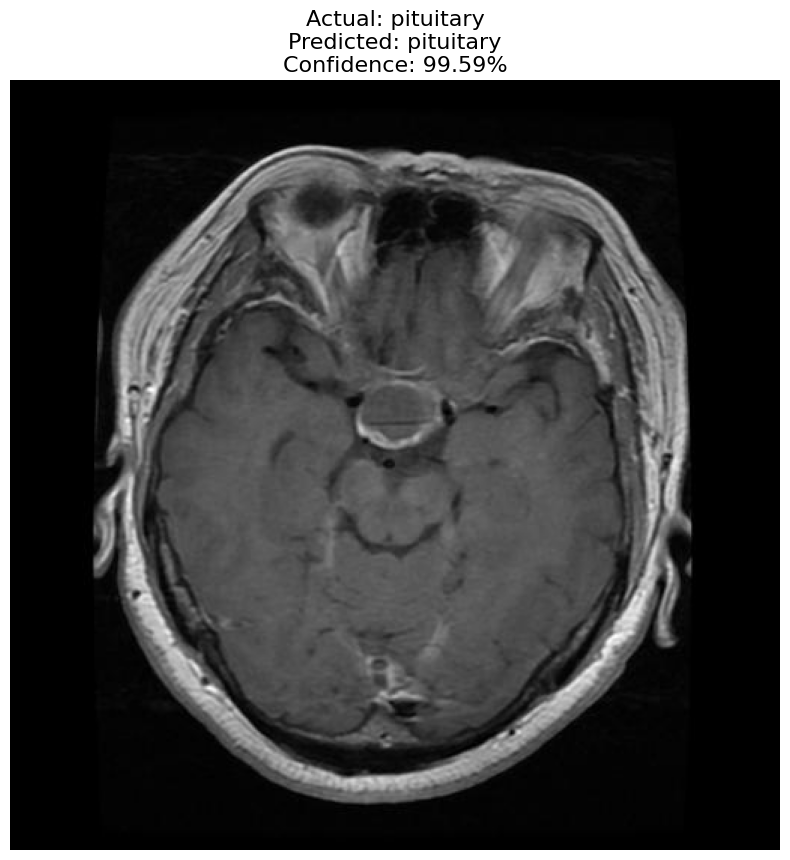

In [57]:
import random
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# Preprocessing must match training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Select a random image from the test dataset
test_dataset = test_loader.dataset
idx = random.randrange(len(test_dataset))

image_tensor, actual_label = test_dataset[idx]
image_path, _ = test_dataset.samples[idx]

# Load original image for display
original_image = Image.open(image_path).convert("RGB")

# Predict
model_mobilenet.eval()

with torch.no_grad():
    outputs = model_mobilenet(image_tensor.unsqueeze(0).to(device))
    probabilities = torch.softmax(outputs, dim=1)[0]
    predicted_label = probabilities.argmax().item()
    confidence = probabilities[predicted_label].item() * 100

class_names = test_dataset.classes

# Display result
plt.figure(figsize=(8, 9))
plt.imshow(original_image)
plt.axis("off")
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {confidence:.2f}%",
    fontsize=16
)
plt.tight_layout()
plt.show()

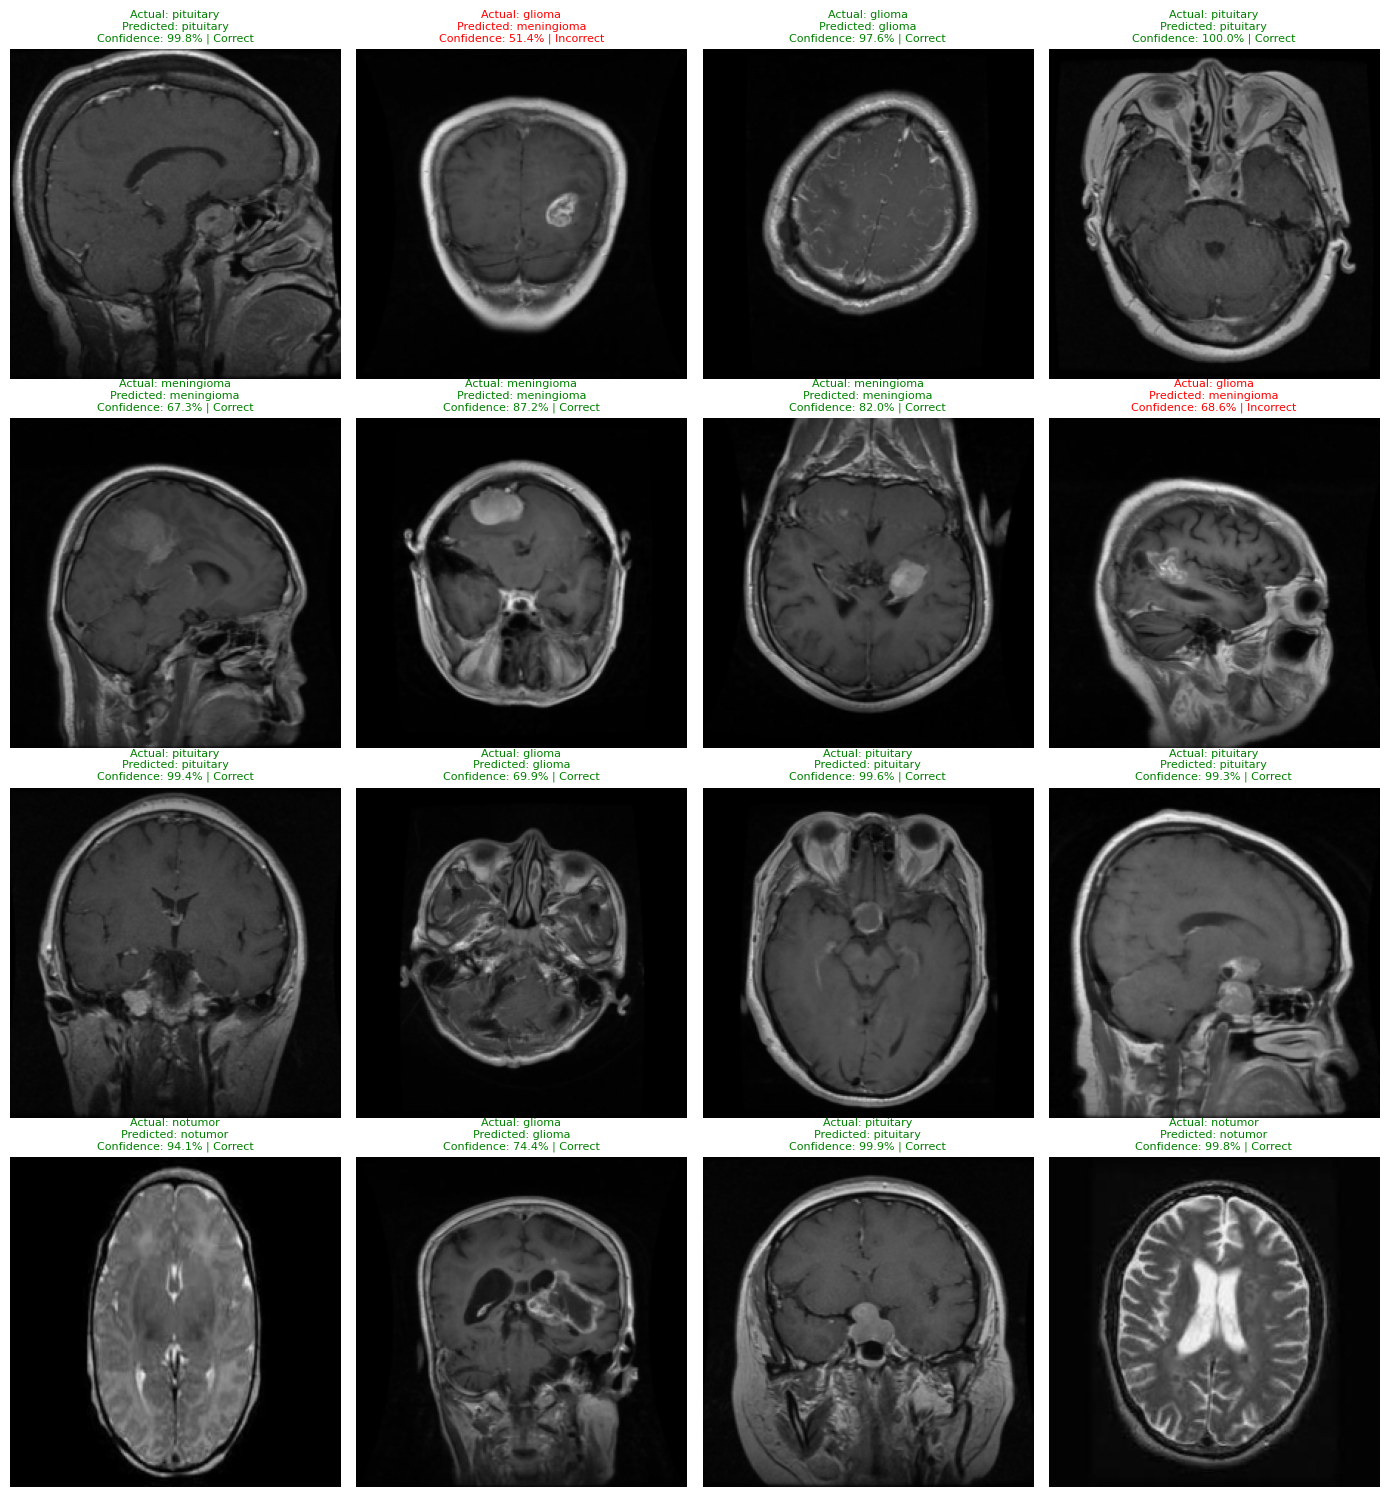

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
import random
import torch
import matplotlib.pyplot as plt
from google.colab import files

test_dataset = test_loader.dataset
class_names = test_dataset.classes

# Randomly select 16 test images
random.seed(42)
indices = random.sample(range(len(test_dataset)), 16)

model_mobilenet.eval()

fig, axes = plt.subplots(4, 4, figsize=(14, 15))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for ax, idx in zip(axes.flat, indices):
    image_tensor, actual_label = test_dataset[idx]

    with torch.no_grad():
        outputs = model_mobilenet(
            image_tensor.unsqueeze(0).to(device)
        )
        probabilities = torch.softmax(outputs, dim=1)[0]
        predicted_label = probabilities.argmax().item()
        confidence = probabilities[predicted_label].item() * 100

    # Reverse ImageNet normalization
    display_image = (
        image_tensor.cpu() * std + mean
    ).clamp(0, 1)

    ax.imshow(display_image.permute(1, 2, 0).numpy())
    ax.axis("off")

    correct = predicted_label == actual_label
    status = "Correct" if correct else "Incorrect"

    ax.set_title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1f}% | {status}",
        color="green" if correct else "red",
        fontsize=8
    )

plt.tight_layout()

# Save high-resolution PNG
output_path = "/content/mobilenetv3-prediction-examples.png"

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# Download PNG to your computer
files.download(output_path)

OVERALL MODEL COMPARISON


,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Precision (Weighted),Recall (Weighted),F1 (Weighted),Correct Predictions,Incorrect Predictions,Inference Time (ms/image)
ResNet-50 (RadImageNet),82.12%,82.53%,82.12%,81.48%,82.53%,82.12%,81.48%,1314.000000,286.000000,3.10
MobileNetV3-Large,88.44%,88.97%,88.44%,88.12%,88.97%,88.44%,88.12%,1415.000000,185.000000,0.94



CLASSIFICATION REPORT: ResNet-50 (RadImageNet)
              precision    recall  f1-score   support

      glioma     0.8967    0.6725    0.7686       400
  meningioma     0.7593    0.6625    0.7076       400
     notumor     0.7837    0.9875    0.8739       400
   pituitary     0.8613    0.9625    0.9091       400

    accuracy                         0.8213      1600
   macro avg     0.8253    0.8212    0.8148      1600
weighted avg     0.8253    0.8213    0.8148      1600


CLASSIFICATION REPORT: MobileNetV3-Large
              precision    recall  f1-score   support

      glioma     0.9666    0.7225    0.8269       400
  meningioma     0.8182    0.8325    0.8253       400
     notumor     0.8780    0.9900    0.9307       400
   pituitary     0.8962    0.9925    0.9419       400

    accuracy                         0.8844      1600
   macro avg     0.8897    0.8844    0.8812      1600
weighted avg     0.8897    0.8844    0.8812      1600



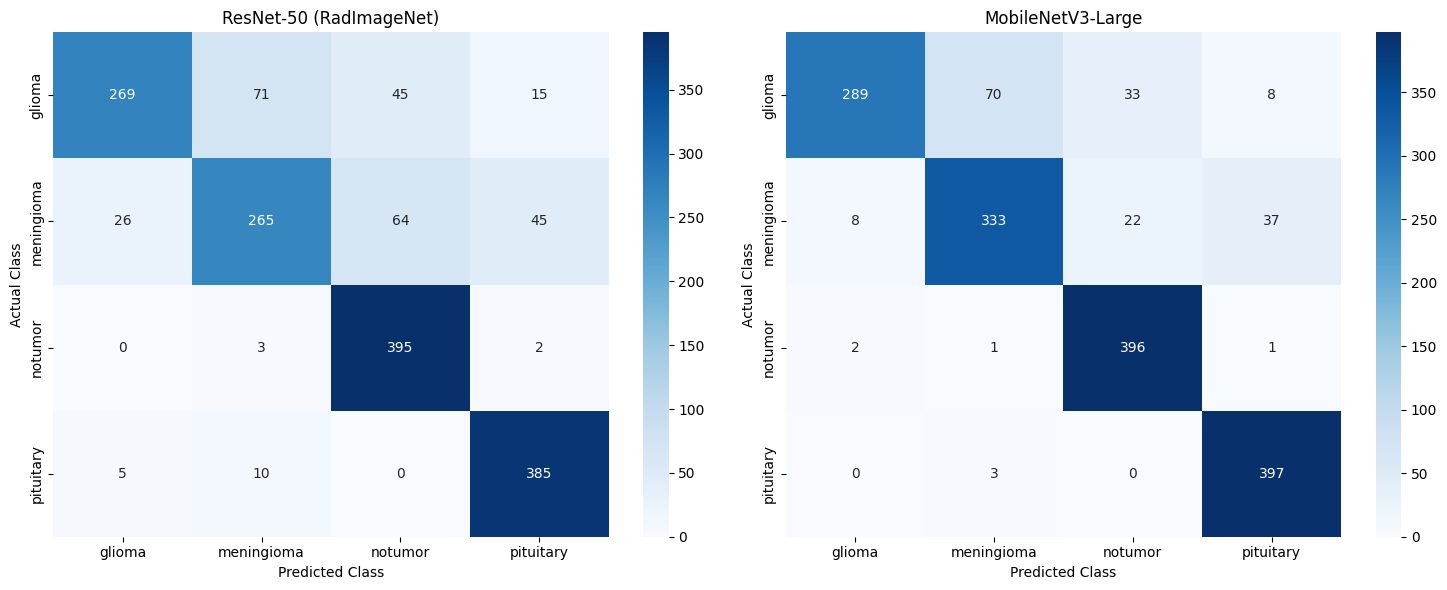

In [63]:
import torch
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models_to_compare = {
    "ResNet-50 (RadImageNet)": model_resnet,
    "MobileNetV3-Large": model_mobilenet
}

class_names = test_loader.dataset.classes
results = {}
predictions_store = {}

for model_name, current_model in models_to_compare.items():
    current_model.eval()

    y_true = []
    y_pred = []
    total_inference_time = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            start_time = time.perf_counter()
            outputs = current_model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            total_inference_time += time.perf_counter() - start_time

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    predictions_store[model_name] = (y_true, y_pred)

    results[model_name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Precision (Weighted)": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall (Weighted)": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 (Weighted)": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Correct Predictions": sum(
            actual == predicted
            for actual, predicted in zip(y_true, y_pred)
        ),
        "Incorrect Predictions": sum(
            actual != predicted
            for actual, predicted in zip(y_true, y_pred)
        ),
        "Inference Time (ms/image)": (
            total_inference_time / len(y_true) * 1000
        )
    }

# Overall comparison table
comparison_df = pd.DataFrame(results).T

print("=" * 75)
print("OVERALL MODEL COMPARISON")
print("=" * 75)

display(comparison_df.style.format({
    "Accuracy": "{:.2%}",
    "Precision (Macro)": "{:.2%}",
    "Recall (Macro)": "{:.2%}",
    "F1 (Macro)": "{:.2%}",
    "Precision (Weighted)": "{:.2%}",
    "Recall (Weighted)": "{:.2%}",
    "F1 (Weighted)": "{:.2%}",
    "Inference Time (ms/image)": "{:.2f}"
}))

# Detailed per-class reports
for model_name, (y_true, y_pred) in predictions_store.items():
    print(f"\n{'=' * 60}")
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 60)

    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (model_name, (y_true, y_pred)) in zip(
    axes, predictions_store.items()
):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names)))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()